## Importing Dependencies

In [11]:
import os 
from pathlib import Path
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
from langchain_community.document_loaders import PyPDFLoader

# Importing Model and API

In [75]:
load_dotenv()

api_key = os.getenv("LANGCHAIN_API_KEY")

if api_key:
    print("API fetch successful")
else:
    print("Api Error")


API fetch successful


In [76]:
llm = ChatOpenAI(
    base_url="https://openrouter.ai/api/v1",
    api_key=api_key,
    model="nvidia/nemotron-3.5-lightning:free",
)

# Document Loader and Splitter

In [77]:
loader = PyPDFLoader("../resource/muse.pdf")
docs = loader.load()

In [78]:
print(docs)
print(len(docs))

[Document(metadata={'producer': 'GPL Ghostscript 9.55.0', 'creator': 'AI Agents Library', 'creationdate': "D:20260922130702Z00'00'", 'moddate': "D:20260922130702Z00'00'", 'author': 'AI Agents Library', 'title': 'How to Use Meta Muse: Beginner Tutorial + 10 Things to Try', 'subject': 'Beginner guide to using Meta Muse', 'keywords': '', 'source': '../resource/muse.pdf', 'total_pages': 10, 'page': 0, 'page_label': '1'}, page_content='AI AGENTS LIBRARY BEGINNER GUIDE / 2026\nFREE PDF GUIDE\nHow to Use\nMeta Muse\nBeginner Tutorial + 10 Things to Try\nSet permissions, connect apps, give Muse its first tasks, and try 10 practical workflows - from reminders\nand research to dashboards, forms, and goal planning.\nLast verified: September 22, 2026\nSource: Meta Muse Help Center + official Muse page\nNote: Research-based guide; AI Agents Library has not completed a hands-on Muse test yet.\nGet Your Free AI Roadmap\naiagentslibrary.com'), Document(metadata={'producer': 'GPL Ghostscript 9.55.0', '

In [79]:
print(list(vars(docs[0]).keys()))

['id', 'metadata', 'page_content', 'type']


In [80]:
print(docs[0])

page_content='AI AGENTS LIBRARY BEGINNER GUIDE / 2026
FREE PDF GUIDE
How to Use
Meta Muse
Beginner Tutorial + 10 Things to Try
Set permissions, connect apps, give Muse its first tasks, and try 10 practical workflows - from reminders
and research to dashboards, forms, and goal planning.
Last verified: September 22, 2026
Source: Meta Muse Help Center + official Muse page
Note: Research-based guide; AI Agents Library has not completed a hands-on Muse test yet.
Get Your Free AI Roadmap
aiagentslibrary.com' metadata={'producer': 'GPL Ghostscript 9.55.0', 'creator': 'AI Agents Library', 'creationdate': "D:20260922130702Z00'00'", 'moddate': "D:20260922130702Z00'00'", 'author': 'AI Agents Library', 'title': 'How to Use Meta Muse: Beginner Tutorial + 10 Things to Try', 'subject': 'Beginner guide to using Meta Muse', 'keywords': '', 'source': '../resource/muse.pdf', 'total_pages': 10, 'page': 0, 'page_label': '1'}


In [81]:
print(docs[1].page_content)

AI AGENTS LIBRARY HOW TO USE META MUSE
FREE AI ROADMAP
3 questions. 20 seconds. Find your best AI tool + first workflow.
OPEN ROADMAP  > 2
QUICK START
Start Here: The 60-Second Version
QUICK ANSWER
You use Meta Muse by chatting with it. Sign in with a Meta account, set how often Muse must ask
before it acts under Settings > Permissions, then connect one app under Settings > Connectors. Start
with a clear, low-risk task. Files Muse creates appear in the Library, reminders under Upcoming, and
completed actions in the Activity log.
Muse is Meta's personal AI agent. Unlike a chatbot that only answers, Muse can take actions for you -
including setting reminders, creating files, researching the web, filling forms in its own browser, and
working through connected apps.
If you still need access, pricing, or the broad overview, see the complete Meta Muse guide.
What this guide covers
01   What You Need Before You Start
02   How to Use Meta Muse, Step by Step
03   Where to Find Everything in the

In [82]:
# Splitting the document

from langchain_text_splitters import RecursiveCharacterTextSplitter

splitter = RecursiveCharacterTextSplitter(
    chunk_size = 400,
    chunk_overlap = 80
)

chunks = splitter.split_documents(docs)

print(len(chunks))

55


In [83]:
print(f"----------\n{chunks}\n")
print(f"----------\n{list(vars(chunks[0]).keys())}\n")
print(f"----------\n{chunks[0].page_content}\n")
print(f"----------\n{chunks[1].page_content}\n")
print(f"----------\n{chunks[2].page_content}\n")
print(f"----------\n{chunks[3].page_content}")

----------
[Document(metadata={'producer': 'GPL Ghostscript 9.55.0', 'creator': 'AI Agents Library', 'creationdate': "D:20260922130702Z00'00'", 'moddate': "D:20260922130702Z00'00'", 'author': 'AI Agents Library', 'title': 'How to Use Meta Muse: Beginner Tutorial + 10 Things to Try', 'subject': 'Beginner guide to using Meta Muse', 'keywords': '', 'source': '../resource/muse.pdf', 'total_pages': 10, 'page': 0, 'page_label': '1'}, page_content='AI AGENTS LIBRARY BEGINNER GUIDE / 2026\nFREE PDF GUIDE\nHow to Use\nMeta Muse\nBeginner Tutorial + 10 Things to Try\nSet permissions, connect apps, give Muse its first tasks, and try 10 practical workflows - from reminders\nand research to dashboards, forms, and goal planning.\nLast verified: September 22, 2026\nSource: Meta Muse Help Center + official Muse page'), Document(metadata={'producer': 'GPL Ghostscript 9.55.0', 'creator': 'AI Agents Library', 'creationdate': "D:20260922130702Z00'00'", 'moddate': "D:20260922130702Z00'00'", 'author': 'AI A

# Create Embeedings

In [94]:
from openai import OpenAI
from langchain_openai import OpenAIEmbeddings
from langchain_community.vectorstores import FAISS

load_dotenv()

embedding_api=os.getenv("OPENROUTER_EMBEDDING_API")
if embedding_api:
  print(f"\n{embedding_api[20]}\n")
else:
  print("None")

client = OpenAI(
  base_url="https://openrouter.ai/api/v1",
  api_key=embedding_api,
)

embeddings = OpenAIEmbeddings(
    model="nvidia/nemotron-3.5-embed-1b:free",
    base_url="https://openrouter.ai/api/v1",
    api_key=embedding_api,
    check_embedding_ctx_length=False,  # Necessary for non-OpenAI backends
    model_kwargs={"encoding_format": "float"}
)

vector_store = FAISS.from_documents(chunks,embeddings)

print(vector_store)


a



In [98]:
#Create a retriever 

retriever = vector_store.as_retriever(search_type='similarity',search_kwargs={'k':4})

# RAG Tool

In [108]:
test_result = retriever.invoke("How to use muse AI?")
print(f"----------\n{type(test_result)}\n")
print(f"----------\n{len(test_result)}\n")
print(f"----------\n{test_result}\n")
print([doc.metadata.get("page") for doc in test_result])
print(f"----------\n{list(vars(test_result[0]).keys())}\n")


----------
<class 'list'>

----------
4

----------
[Document(id='d4312e6e-a911-43f6-a541-5446a4cabaa8', metadata={'producer': 'GPL Ghostscript 9.55.0', 'creator': 'AI Agents Library', 'creationdate': "D:20260922130702Z00'00'", 'moddate': "D:20260922130702Z00'00'", 'author': 'AI Agents Library', 'title': 'How to Use Meta Muse: Beginner Tutorial + 10 Things to Try', 'subject': 'Beginner guide to using Meta Muse', 'keywords': '', 'source': '../resource/muse.pdf', 'total_pages': 10, 'page': 7, 'page_label': '8'}, page_content='Frequently Asked Questions\nHow do I start using Meta Muse?\nOpen Muse in the Muse app, at muse.ai, on a Mac or in WhatsApp, and sign in with a Meta account. Muse\nopens on the Chat tab, where you type what you want done. Set your permissions under Settings >\nPermissions before connecting any apps.'), Document(id='aff66e5b-1193-4f0f-8c47-2480efe9cc44', metadata={'producer': 'GPL Ghostscript 9.55.0', 'creator': 'AI Agents Library', 'creationdate': "D:20260922130702Z

In [110]:
from langchain_core.tools import  tool

@tool
def rag_tool(query):
    """
    This tool retrieves any relevant information from the pdf document. Use this tool when user asks questions that might be answered form the stored document. 
    When not to use : When the general query can be answered without making tool call
    """
    result = retriever.invoke(query)
    context = [doc_content.page_content for doc_content in result]
    metadata = [doc_content.metadata for doc_content in result]
    return {
        'query':query,
        'metadata':metadata,
        'content':context
    }

In [111]:
tools = [rag_tool]
llm_with_tools = llm.bind_tools(tools)

# Creating ChatState and Graph

In [127]:
from typing import TypedDict, Annotated

from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition

from langchain_core.messages import BaseMessage, HumanMessage

from IPython.display import display, Image

In [117]:
class ChatState(TypedDict):
    messages : Annotated[list[BaseMessage],add_messages]

In [136]:
def chat_node(state:ChatState):
    messages = state['messages']
    llm_response = llm_with_tools.invoke(messages)
    return {'messages':[llm_response]}

tool_node = ToolNode(tools)

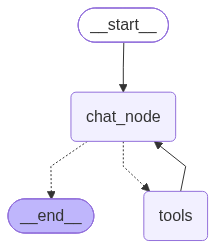

In [137]:
# Creting Graph, nodes and edges


graph = StateGraph(ChatState)

graph.add_node("chat_node",chat_node)
graph.add_node("tools",tool_node)

graph.add_edge(START,"chat_node")
graph.add_conditional_edges("chat_node",tools_condition)
graph.add_edge("tools","chat_node")

workflow = graph.compile()

display(Image(workflow.get_graph().draw_mermaid_png()))

# User Input

In [138]:
user_query = input("Enter Query")

user_input = {
    'messages':[HumanMessage(content=user_query)]
}

llm_output = workflow.invoke(user_input)

print(llm_output)

/home/program/.pyenv/versions/3.11.9/lib/python3.11/ast.py:50: RuntimeWarning: coroutine 'RunnableBindingBase.ainvoke' was never awaited
  return compile(source, filename, mode, flags,


OpenAIAuthenticationError: Error code: 401 - {'error': {'message': 'Missing Authentication header', 'code': 401}}